In [6]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

def ansatz(num_qubits):
    return real_amplitudes(num_qubits, reps=2)

In [86]:
from tensorflow.keras import layers, Model
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer.primitives import Sampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.optimizers import COBYLA
import matplotlib.pyplot as plt
import time

# --------------------------
# 1️⃣ Feature extraction from QAE
# --------------------------
from qiskit import QuantumCircuit
import numpy as np
from tqdm import tqdm

def extract_qae_features(ae_circ, qnn, data, params, num_latent, num_trash, batch_size=64):
    """
    Extract QAE features (p0, p1 from SWAP-test) for a dataset.

    Parameters:
        ae_circ : QuantumCircuit
            The trained autoencoder circuit template (unbound).
        qnn : SamplerQNN
            QNN wrapper with Sampler backend.
        data : np.ndarray or tf.Tensor
            Input data (num_samples, num_features).
        params : array-like
            Trained parameters for the autoencoder.
        encoding_fn : callable
            Function to encode classical data into a quantum circuit.
        num_latent : int
            Number of latent qubits.
        num_trash : int
            Number of trash qubits.
        batch_size : int
            Number of samples per batch.

    Returns:
        features : np.ndarray
            Array of shape (num_samples, 2) with [p0, p1] features.
    """

    total_qubits = num_latent + 2 * num_trash + 1
    num_encoding_qubits = num_latent + num_trash
    features = []

    # Ensure data is NumPy array
    if hasattr(data, "numpy"):
        data = data.numpy()

    # Assign trained parameters once
    ae_circ = ae_circ.assign_parameters({p: v for p, v in zip(ae_circ.parameters, params)})

    for i in tqdm(range(0, len(data), batch_size), desc="Extracting QAE features"):
        batch = data[i : i + batch_size]

        circuits = []
        for x in batch:

            N = 2 * num_encoding_qubits
            input_slice = x[:N] * np.pi  # scale to [0, π]

            # --- Build circuit ---
            enc_circ = dense_angle_encoding(input_slice)
            full_circ = QuantumCircuit(total_qubits, 1)
            full_circ.compose(enc_circ, qubits=range(enc_circ.num_qubits), inplace=True)
            full_circ.compose(ae_circ, inplace=True)

            circuits.append(full_circ)

        # --- Run batch ---
        job = qnn.sampler.run(circuits)
        result = job.result()

        # --- Extract features ---
        for quasi in result.quasi_dists:
            p0 = quasi.get(0, 0)
            p1 = quasi.get(1, 0)
            features.append([p0, p1])

    return np.array(features)

# Noise generation function for NCE
def generate_nce_noise(X, noise_ratio=1.0, perturb_std=0.5):
    """
    Generate negative samples for NCE training.
    Combines feature shuffling and Gaussian perturbation.
    
    Args:
        X: np.ndarray of normal samples
        noise_ratio: multiplier for how many noise samples to generate vs normal
        perturb_std: scaling factor for Gaussian noise
    Returns:
        np.ndarray of synthetic anomalies
    """
    n_samples = int(len(X) * noise_ratio)
    noise = np.copy(X[np.random.choice(len(X), n_samples, replace=True)])

    # Step 1: Feature shuffle (destroys correlations)
    for col in range(noise.shape[1]):
        np.random.shuffle(noise[:, col])

    # Step 2: Gaussian perturbation
    col_std = np.std(X, axis=0)
    noise += np.random.normal(0, perturb_std * col_std, size=noise.shape)

    return noise


In [67]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.
        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result


In [68]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [79]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

reduced_anomalous_training_data = anomalous_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_anomalous_training_data = scaler.fit_transform(reduced_anomalous_training_data)

reduced_validation_data = validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_validation_data = scaler.fit_transform(reduced_validation_data)

In [70]:
from qiskit.qpy import load
from qiskit_aer.primitives import Sampler

model_name = "8f_qae_dense_ra2_5k"
model_path = "Models/QAE/First_N/"

with open(f"{model_path + model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
    
weight_names = np.load(f"{model_path + model_name}/weight_param_names.npy", allow_pickle=True)
weight_params = [p for p in ae.parameters if p.name in weight_names]
trained_params = np.load(f"{model_path + model_name}/trained_parameters.npy")

num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  

dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)
sampler = Sampler()

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=weight_params,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

C:\Users\Rohan\AppData\Local\Temp\ipykernel_14108\832375489.py:22: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [122]:
# --------------------------
# 3️⃣ Full training pipeline
# --------------------------
# QAE already trained using COBYLA as in your code
# `trained_params` is the optimized AE parameters
training_subset = scaled_normal_training_data[:5000]

# 3a. Extract QAE features from normal training data
features_normal = extract_qae_features(
    ae, qnn, training_subset, trained_params, num_latent, num_trash
)

# 3b. Generate "noise" for NCE training
# noise_features = features_normal + np.random.normal(0, 0.05, features_normal.shape)
# noise_features = generate_nce_noise(features_normal, noise_ratio=1.0, perturb_std=0.05)
noise_features = extract_qae_features(ae, qnn, anomalous_training_data[:5000], trained_params, num_latent, num_trash)


X_nce_train = np.vstack([features_normal, noise_features])
y_nce_train = np.hstack([np.ones(len(features_normal)), np.zeros(len(noise_features))])

# 3c. Build and train NCE classifier
nce_model = build_nce_classifier(input_dim=X_nce_train.shape[1])
nce_model.fit(X_nce_train, y_nce_train, epochs=200, batch_size=64, validation_split=0.1)

Extracting QAE features: 100%|█████████████████████████████████████████████████████████| 20/20 [00:06<00:00,  3.05it/s]

Epoch 1/200


89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8862 - loss: 0.5585 - val_accuracy: 0.0000e+00 - val_loss: 1.0234
Epoch 2/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.4294 - val_accuracy: 0.0000e+00 - val_loss: 1.3162
Epoch 3/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.3520 - val_accuracy: 0.0000e+00 - val_loss: 1.5294
Epoch 4/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.3233 - val_accuracy: 0.0000e+00 - val_loss: 1.5372
Epoch 5/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.3099 - val_accuracy: 0.0000e+00 - val_loss: 1.4443
Epoch 6/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.2989 - val_accuracy: 0.0000e+00 - val_loss: 1.2994
Epoch 7/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8862 - loss: 0.2880 - val_accuracy: 0.0000e+00 - val_loss: 1.1357
Epoch 8/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8945 - loss: 0.2664 - val_accu

In [189]:
from sklearn.ensemble import IsolationForest

nce_train_scores = 1- nce_model.predict(features_normal).flatten() 
iso_forest = IsolationForest(contamination=0.005, random_state=42)
# Reshape scores to column vector (n_samples, 1)
nce_train_scores = nce_train_scores.reshape(-1, 1)
# Concatenate: [original features, NCE score]
train_vector = np.hstack([nce_train_scores])
iso_forest.fit(train_vector) 

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step


,n_estimators,100
,max_samples,'auto'
,contamination,0.005
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [190]:
# --------------------------
# 4️⃣ Anomaly scoring
# --------------------------
# features_test = extract_qae_features(ae, qnn, testing_data, trained_params, num_latent, num_trash)
nce_scores = 1 - nce_model.predict(features_test).flatten()  # higher = more anomalous
nce_scores = nce_scores.reshape(-1,1)
test_vector = np.hstack([nce_scores])
preds = iso_forest.predict(test_vector)  # -1 = anomaly, 1 = normal
preds = np.where(preds == -1, 1, 0)  # Convert to 0=normal, 1=anomaly

scores = iso_forest.decision_function(test_vector) 

5906/5906 ━━━━━━━━━━━━━━━━━━━━ 2s 415us/step


In [191]:
threshold = np.mean(scores) + 1 * np.std(scores)   # simple threshold
threshold = -0.054
predictions = (scores < threshold).astype(int)
y_true = testing_labels

metrics = evaluate_model(
    y_true=y_true,
    y_pred=predictions,
    scores=scores,
    time=0,
    threshold=threshold,
    model_name="8F Classical AE"
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")


Model: 8F Classical AE
Precision: 0.000
Accuracy: 0.093
Recall: 0.000
F1-Score: 0.000
Matrix: TP=0, FP=0, FN=171459, TN=17508
AUROC: 0.034
Data Loading + Inference Time (s): 0.0000s
Clf Report: precision    recall  f1-score   support

       False       0.09      1.00      0.17     17508
        True       0.00      0.00      0.00    171459

    accuracy                           0.09    188967
   macro avg       0.05      0.50      0.08    188967
weighted avg       0.01      0.09      0.02    188967


C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

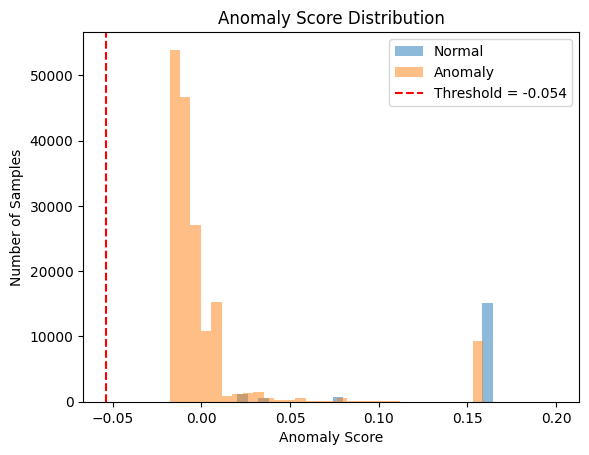

In [192]:
import matplotlib.pyplot as plt
# --- Histogram of scores ---
plt.hist(scores[y_true.numpy() == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true.numpy() == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()